# Experimento A/B: efecto de la publicidad en la conversión

**La pregunta de negocio.** ¿Mostrar publicidad comercial aumenta la conversión frente a mostrar un anuncio de servicio público? ¿Cuánto, con qué seguridad y a qué costo vale la pena?

## Guía de lectura

**Qué vas a aprender**

- A auditar un experimento antes de mirar su resultado.
- A separar el efecto, su incertidumbre y su valor económico.
- A comprobar una conclusión con varios métodos.
- A evitar errores comunes: filtrar por variables posteriores y buscar subgrupos ganadores.
- A dimensionar un experimento antes de hacerlo.

**Mapa del notebook**

| Sección | Pregunta que responde |
|---|---|
| 1. Problema y configuración | ¿Qué queremos medir? |
| 2. Auditoría de datos | ¿El registro es confiable? |
| 3. Balance entre grupos | ¿Los grupos son comparables? |
| 4. Efecto principal | ¿Cuánto cambia la conversión? |
| 5. Comprobaciones | ¿Otros métodos dicen lo mismo? |
| 6. Ajustes y sesgo | ¿El resultado depende de otras variables? |
| 7. Subgrupos | ¿El efecto es igual para todos? |
| 8. Potencia | ¿Qué tamaño necesitaba el experimento? |
| 9. Decisión económica | ¿Conviene hacerlo? |
| 10. Limitaciones | ¿Qué no sabemos? |
| Conclusión | ¿Qué recomendamos? |

### Glosario rápido

| Término | Significado |
|---|---|
| **Tratamiento** | Grupo que ve publicidad comercial (`ad`) |
| **Control** | Grupo que ve un anuncio de servicio público (`psa`) |
| **pp** | Puntos porcentuales: de 1.8 % a 2.6 % son 0.8 pp |
| **Valor p** | Probabilidad de observar una diferencia así si en realidad no hubiera efecto |
| **Intervalo de confianza (IC)** | Rango de valores compatibles con los datos |
| **SMD** | Diferencia entre grupos medida en desviaciones estándar |
| **Odds ratio** | Comparación de las chances de convertir entre dos grupos |
| **Efecto mínimo detectable** | Menor efecto que el experimento podría distinguir del azar |
| **Variable posterior** | Variable que se mide después de asignar el tratamiento |

## 1. Definición del problema y configuración

| Elemento | Definición |
|---|---|
| **Unidad de análisis** | Un usuario |
| **Tratamiento** | Publicidad comercial (`ad`) |
| **Control** | Anuncio de servicio público (`psa`) |
| **Métrica principal** | Conversión: `converted` |
| **Pregunta causal** | Efecto de ver el anuncio frente a ver un anuncio de servicio público |

**Datos.** *Marketing A/B Testing* de Kaggle. Es un caso publicitario general y no una campaña bancaria.

**Qué mide y qué no.** El control ve otro anuncio, así que medimos publicidad comercial **frente a un anuncio de servicio público**, no frente a no mostrar nada.

**Supuesto central.** Una lectura causal exige que el grupo se haya asignado al azar. El archivo no incluye el protocolo del experimento.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40, 'display.max_rows', 120, 'display.width', 200)

### Los parámetros del estudio

| Parámetro | Valor | Qué significa |
|---|---|---|
| `ALFA` | 0.05 | Probabilidad aceptada de un falso positivo |
| `POTENCIA` | 0.80 | Probabilidad de detectar un efecto real del tamaño buscado |
| `UMBRAL_SMD` | 0.10 | Referencia habitual para considerar relevante un desbalance |
| `MARGEN_CONVERSION` | 50 | Valor ilustrativo de cada conversión adicional |
| `COSTOS_POR_MIL` | 100 a 500 | Escenarios de costo por cada 1,000 usuarios |
| `N_PERMUTACIONES`, `N_AA` | 2,000 | Repeticiones para las comprobaciones |
| `N_POSTERIOR` | 200,000 | Simulaciones para el análisis bayesiano |

> **Criterio.** El archivo no trae costos ni márgenes. La decisión económica es un ejemplo, y debe repetirse con valores reales.

In [3]:
# Análisis
ALFA = 0.05
POTENCIA = 0.80
UMBRAL_SMD = 0.10         # diferencia estandarizada a partir de la cual revisamos un desbalance

# Economía (valores ilustrativos: el archivo no los trae)
MARGEN_CONVERSION = 50
COSTOS_POR_MIL = [100, 200, 300, 400, 500]

# Remuestreo
SEMILLA, N_PERMUTACIONES, N_AA, N_POSTERIOR = 11, 2000, 2000, 200000

AZUL, NARANJA, VERDE, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})


In [4]:
def pct(x, d=2):
    return f'{100 * x:.{d}f} %'

def pp(x, d=3):
    return f'{100 * x:+.{d}f} pp'

## 2. Auditoría de datos

Antes de mirar el efecto, comprobamos que cada usuario aparezca una sola vez y que los registros sean válidos.

In [5]:
candidatas = [Path('data/marketing_AB.csv.zip'), Path('data/marketing_AB.csv'), Path('marketing_AB.csv.zip'),
              Path.home() / 'Downloads' / 'marketing_AB.csv.zip']
ruta = next(p for p in candidatas if p.is_file())
crudo = pd.read_csv(ruta)
assert crudo.shape == (588101, 7), 'El archivo no coincide con la versión esperada'
df = crudo.drop(columns='Unnamed: 0').rename(columns={'user id': 'usuario', 'test group': 'grupo', 'converted': 'convirtio', 'total ads': 'anuncios',
                                                       'most ads day': 'dia', 'most ads hour': 'hora'})
assert df['usuario'].is_unique and df.isna().sum().sum() == 0 and set(df['grupo']) == {'ad', 'psa'}
df['ad'] = (df['grupo'] == 'ad').astype(int)
df['y'] = df['convirtio'].astype(int)
ORDEN_DIAS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

controles = pd.DataFrame([
    ('Usuarios duplicados', int(df['usuario'].duplicated().sum()), 'Ninguno'),
    ('Valores faltantes', int(df.isna().sum().sum()), 'Ninguno'),
    ('Usuarios con cero anuncios', int((df['anuncios'] == 0).sum()), 'Todos recibieron al menos uno'),
    ('Horas fuera de 0 a 23', int((~df['hora'].between(0, 23)).sum()), 'Ninguna'),
], columns=['Control', 'Casos', 'Resultado']).set_index('Control')
display(controles)

t = df.groupby('grupo')['y'].agg(usuarios='size', conversiones='sum', tasa='mean')
t['% de usuarios'] = t['usuarios'] / t['usuarios'].sum()
display(t.assign(tasa=t['tasa'].map(pct), **{'% de usuarios': t['% de usuarios'].map(pct)}))
print(f"Máximo de anuncios: {df['anuncios'].max():,} | Percentil 99: {df['anuncios'].quantile(.99):.0f} | Mediana: {df['anuncios'].median():.0f}")

,Casos,Resultado
Control,,
Usuarios duplicados,0,Ninguno
Valores faltantes,0,Ninguno
Usuarios con cero anuncios,0,Todos recibieron al menos uno
Horas fuera de 0 a 23,0,Ninguna


,usuarios,conversiones,tasa,% de usuarios
grupo,,,,
ad,564577,14423,2.55 %,96.00 %
psa,23524,420,1.79 %,4.00 %


Máximo de anuncios: 2,065 | Percentil 99: 202 | Mediana: 13


**Lectura.**

- **El registro está limpio:** 588,101 usuarios únicos y sin faltantes. La columna `Unnamed: 0` es un índice y se elimina.
- **El reparto es 96 % / 4 %.** El control tiene 23,524 usuarios. No podemos saber si ese reparto era el planeado, porque el archivo no lo indica. Sin esa cifra no se puede hacer una prueba formal de desbalance de asignación.
- **Hay usuarios con exposición extrema:** la mediana es 13 anuncios, y el máximo llega a 2,065.

## 3. Balance entre grupos

Si la asignación fue aleatoria, los grupos deberían parecerse en todo. No tenemos variables anteriores al experimento, así que revisamos las disponibles, **aunque se midieron después de la asignación**.

**Cómo leer la tabla.** Con casi 600,000 usuarios, hasta una diferencia mínima da un valor p muy pequeño. Por eso miramos también el **SMD**: una diferencia en desviaciones estándar que no depende del tamaño de muestra.

**Ejemplo.** Si dos grupos difieren en 0.72 puntos de una variable cuya desviación estándar es 10, entonces $SMD = 0.72 / 10 = 0.072$.

In [6]:
def smd_categoria(col):
    p_ = pd.crosstab(df[col], df['grupo'], normalize='columns')
    agrup = np.sqrt((p_['ad'] * (1 - p_['ad']) + p_['psa'] * (1 - p_['psa'])) / 2)
    return ((p_['ad'] - p_['psa']) / agrup).abs()

a_, p_ = df.loc[df['ad'] == 1, 'anuncios'], df.loc[df['ad'] == 0, 'anuncios']
smd_anuncios = abs(np.log1p(a_).mean() - np.log1p(p_).mean()) / np.sqrt((np.log1p(a_).var() + np.log1p(p_).var()) / 2)
filas = [{'Variable': 'Log de anuncios vistos', 'Mayor SMD': round(smd_anuncios, 3),
          'p (Kolmogorov-Smirnov)': f'{stats.ks_2samp(a_, p_).pvalue:.3g}'}]
for col, nombre in [('dia', 'Día con más anuncios'), ('hora', 'Hora con más anuncios')]:
    filas.append({'Variable': nombre, 'Mayor SMD': round(smd_categoria(col).max(), 3),
                  'p (chi cuadrado)': f"{stats.chi2_contingency(pd.crosstab(df[col], df['grupo']))[1]:.3g}"})
display(pd.DataFrame(filas).set_index('Variable').fillna('-'))
reparto = pd.crosstab(df['dia'], df['grupo'], normalize='columns').loc[ORDEN_DIAS]
display((reparto * 100).round(2).assign(Diferencia=lambda x: (x['ad'] - x['psa']).round(2)))

,Mayor SMD,p (Kolmogorov-Smirnov),p (chi cuadrado)
Variable,,,
Log de anuncios vistos,0.040,2.34e-31,-
Día con más anuncios,0.072,-,4.85e-48
Hora con más anuncios,0.048,-,1.09e-28


grupo,ad,psa,Diferencia
dia,,,
Monday,14.80,14.89,-0.09
Tuesday,13.21,12.36,0.85
Wednesday,13.71,14.84,-1.13
Thursday,14.01,16.60,-2.59
Friday,15.73,16.17,-0.44
Saturday,13.96,12.15,1.81
Sunday,14.58,13.00,1.58


**Lectura.** Todos los valores p son diminutos, pero el mayor SMD es 0.072, por debajo de la referencia de 0.10. Las diferencias son pequeñas en magnitud. La mayor está en los jueves, con 2.59 puntos menos en el grupo de anuncios. Es una señal menor que convendría preguntar al equipo del experimento, y no invalida por sí sola el análisis.

## 4. Efecto principal

Medimos la diferencia de tasas entre grupos y su incertidumbre. La prueba z evalúa la hipótesis de que no hay diferencia:

$$z = \frac{\hat p_A - \hat p_C}{\sqrt{\bar p (1 - \bar p)\left(\frac{1}{n_A} + \frac{1}{n_C}\right)}}$$

Comparamos dos intervalos: **Wald**, el más habitual, y **Newcombe**, recomendado cuando las tasas son bajas.

,Valor
Tasa con anuncio,2.555 %
Tasa con anuncio de servicio público,1.785 %
Efecto absoluto,+0.769 pp
IC 95 % (Wald),+0.595 pp a +0.943 pp
IC 95 % (Newcombe),+0.587 pp a +0.936 pp
Efecto relativo,+43.1 %
IC 95 % del efecto relativo,+30.0 % a +57.5 %
Estadístico z,7.37
Valor p,1.71e-13
"Conversiones adicionales por 1,000 usuarios",7.69


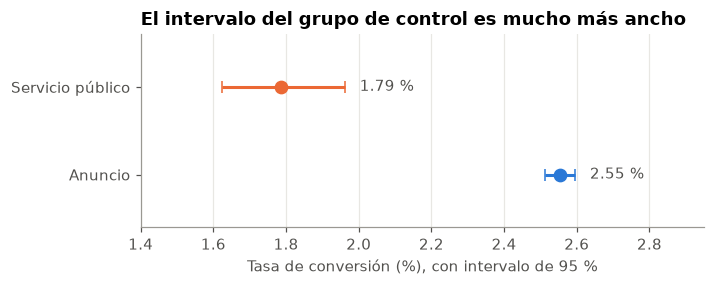

In [7]:
na, nc = int((df['ad'] == 1).sum()), int((df['ad'] == 0).sum())
xa, xc = int(df.loc[df['ad'] == 1, 'y'].sum()), int(df.loc[df['ad'] == 0, 'y'].sum())
pa, pc = xa / na, xc / nc
delta = pa - pc
z_ = stats.norm.ppf(1 - ALFA / 2)
agrup = (xa + xc) / (na + nc)
z_obs = delta / np.sqrt(agrup * (1 - agrup) * (1 / na + 1 / nc))
p_val = 2 * stats.norm.sf(abs(z_obs))
ee = np.sqrt(pa * (1 - pa) / na + pc * (1 - pc) / nc)
li, ls = delta - z_ * ee, delta + z_ * ee
n_li, n_ls = confint_proportions_2indep(xa, na, xc, nc, method='newcomb', compare='diff')
rr = pa / pc
ee_log = np.sqrt(1 / xa - 1 / na + 1 / xc - 1 / nc)
rr_li, rr_ls = np.exp(np.log(rr) - z_ * ee_log), np.exp(np.log(rr) + z_ * ee_log)

display(pd.DataFrame({
    'Valor': {'Tasa con anuncio': pct(pa, 3), 'Tasa con anuncio de servicio público': pct(pc, 3), 'Efecto absoluto': pp(delta),
              'IC 95 % (Wald)': f'{pp(li)} a {pp(ls)}', 'IC 95 % (Newcombe)': f'{pp(n_li)} a {pp(n_ls)}',
              'Efecto relativo': f'{100 * (rr - 1):+.1f} %', 'IC 95 % del efecto relativo': f'{100 * (rr_li - 1):+.1f} % a {100 * (rr_ls - 1):+.1f} %',
              'Estadístico z': round(z_obs, 2), 'Valor p': f'{p_val:.3g}', 'Conversiones adicionales por 1,000 usuarios': round(1000 * delta, 2)}}))

fig, ax = plt.subplots(figsize=(6.6, 2.7))
filas_g = [('Anuncio', pa, xa, na, AZUL), ('Servicio público', pc, xc, nc, NARANJA)]
for i, (n_, p__, x_, m_, color) in enumerate(filas_g):
    b_, a__ = proportion_confint(x_, m_, method='wilson')
    ax.errorbar(100 * p__, i, xerr=[[100 * (p__ - b_)], [100 * (a__ - p__)]], fmt='o', color=color, markersize=8, capsize=4, linewidth=2)
    ax.text(100 * a__ + 0.04, i, f'{100 * p__:.2f} %', va='center', color=TINTA)
ax.set_yticks([0, 1], [f[0] for f in filas_g]); ax.set_ylim(-0.6, 1.6); ax.set_xlim(1.4, 2.95); ax.grid(axis='y', visible=False)
ax.set(xlabel='Tasa de conversión (%), con intervalo de 95 %', title='El intervalo del grupo de control es mucho más ancho')
plt.tight_layout(); plt.show()

**Lectura.**

- **El anuncio aumenta la conversión en 0.769 pp** (IC 95 %: 0.595 a 0.943), de 1.785 % a 2.555 %.
- **En términos relativos es +43.1 %** (entre 30.0 % y 57.5 %).
- **Cada 1,000 usuarios significan cerca de 7.7 conversiones adicionales.** Un valor p pequeño no indica que el efecto sea grande: esta cifra es la que importa para decidir.

El gráfico muestra el costo de un control pequeño: su intervalo es mucho más ancho, y es la principal fuente de incertidumbre del experimento.

## 5. Comprobaciones

Si una conclusión es sólida, no debería depender del método.

| Método | Idea |
|---|---|
| **Fisher** | Prueba exacta, sin aproximaciones |
| **Permutación** | Reasigna las etiquetas al azar y mira qué tan extrema es la diferencia observada |
| **Bootstrap** | Simula muchas réplicas del experimento |
| **Bayesiano** | Entrega directamente la probabilidad de que el anuncio sea mejor |
| **Prueba A/A** | Divide al control en dos mitades sin diferencia real, y comprueba cuántas veces se declara un efecto falso |

Una prueba A/A bien calibrada debería dar falsos positivos cerca del 5 %.

In [8]:
rng = np.random.default_rng(SEMILLA)
N, X = na + nc, xa + xc

# Permutación: si la etiqueta no importara, ¿qué diferencia aparecería?
x_perm = rng.hypergeometric(X, N - X, na, N_PERMUTACIONES)
d_perm = x_perm / na - (X - x_perm) / nc
p_perm = (1 + (np.abs(d_perm) >= abs(delta)).sum()) / (N_PERMUTACIONES + 1)

# Bootstrap
ba = rng.binomial(na, pa, 200000) / na
bc = rng.binomial(nc, pc, 200000) / nc
b_li, b_ls = np.percentile(ba - bc, [2.5, 97.5])

# Prueba exacta
tabla_2x2 = [[xa, na - xa], [xc, nc - xc]]
p_fisher = stats.fisher_exact(tabla_2x2)[1]

# Bayes con priors no informativos
pa_post = rng.beta(1 + xa, 1 + na - xa, N_POSTERIOR)
pc_post = rng.beta(1 + xc, 1 + nc - xc, N_POSTERIOR)
d_post = pa_post - pc_post
display(pd.DataFrame({
    'Método': ['Prueba z', 'Exacta de Fisher', f'Permutación ({N_PERMUTACIONES:,})', 'Bootstrap paramétrico', 'Bayesiano Beta(1,1)'],
    'Efecto o valor p': [f'p = {p_val:.3g}', f'p = {p_fisher:.3g}', f'p ≤ {p_perm:.2g}', f'{pp(ba.mean() - bc.mean())}', f'{pp(d_post.mean())}'],
    'Intervalo de 95 %': [f'{pp(li)} a {pp(ls)}', '-', '-', f'{pp(b_li)} a {pp(b_ls)}', f'{pp(np.percentile(d_post, 2.5))} a {pp(np.percentile(d_post, 97.5))}'],
}).set_index('Método'))
print(f'Probabilidad a posteriori de que el anuncio sea mejor: {(d_post > 0).mean():.4%}')

# Prueba A/A: repartir etiquetas al azar con la misma proporción sobre usuarios que no vieron anuncios comerciales
fp = 0
for _ in range(N_AA):
    x1 = rng.hypergeometric(xc, nc - xc, nc // 2)
    n1, n2 = nc // 2, nc - nc // 2
    pa1, pa2 = x1 / n1, (xc - x1) / n2
    ag = xc / nc
    fp += abs(pa1 - pa2) / np.sqrt(ag * (1 - ag) * (1 / n1 + 1 / n2)) > z_
print(f'Tasa de falsos positivos en pruebas A/A: {fp / N_AA:.2%} (esperado: {ALFA:.0%})')

,Efecto o valor p,Intervalo de 95 %
Método,,
Prueba z,p = 1.71e-13,+0.595 pp a +0.943 pp
Exacta de Fisher,p = 1.05e-14,-
"Permutación (2,000)",p ≤ 0.0005,-
Bootstrap paramétrico,+0.769 pp,+0.593 pp a +0.942 pp
"Bayesiano Beta(1,1)",+0.765 pp,+0.587 pp a +0.937 pp


Probabilidad a posteriori de que el anuncio sea mejor: 100.0000%
Tasa de falsos positivos en pruebas A/A: 5.30% (esperado: 5%)


**Lectura.** Todos los métodos llevan a la misma conclusión, con intervalos casi iguales. El valor de permutación es el mínimo alcanzable con 2,000 repeticiones. La prueba A/A da 5.30 %, cercana al 5 % esperado: la prueba z está bien calibrada en estos datos.

## 6. Ajustes y sesgo

**¿Cambia el resultado al ajustar?** En un experimento aleatorizado, ajustar no debería mover mucho el efecto. Comparamos modelos sin ajuste, con ajuste por día y hora, y Mantel-Haenszel, que compara grupos dentro de cada estrato.

**Cuidado con las variables posteriores.** Día, hora y anuncios vistos se miden después de la asignación, y el tratamiento podría influir en ellas. Por eso estos modelos son solo una comprobación.

**Valor E.** Indica qué tan fuerte tendría que ser un factor oculto para explicar todo el efecto. Se calcula como $RR + \sqrt{RR(RR-1)}$, donde $RR$ es la razón de tasas.

In [9]:
# Mantel-Haenszel por estratos: ajusta por día y hora en los que se concentró la exposición
def mantel(col):
    tablas = []
    for _, g in df.groupby(col):
        v = pd.crosstab(g['ad'], g['y']).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
        tablas.append(v)
    st = StratifiedTable(tablas)
    b_, a__ = st.oddsratio_pooled_confint()
    return st.oddsratio_pooled, b_, a__, st.test_equal_odds().pvalue

X_ = pd.get_dummies(df[['dia']], drop_first=True, dtype=float).assign(ad=df['ad'].astype(float), hora_sin=np.sin(2 * np.pi * df['hora'] / 24), hora_cos=np.cos(2 * np.pi * df['hora'] / 24))
sin_cov = sm.Logit(df['y'], sm.add_constant(df[['ad']].astype(float))).fit(disp=0)
con_cov = sm.Logit(df['y'], sm.add_constant(X_)).fit(disp=0)
con_ads = sm.Logit(df['y'], sm.add_constant(X_.assign(log_anuncios=np.log1p(df['anuncios'])))).fit(disp=0)
base = df['ad'].mean()

def ame(m, XM):
    p1, p0 = m.predict(sm.add_constant(XM).assign(ad=1.0)), m.predict(sm.add_constant(XM).assign(ad=0.0))
    return float((p1 - p0).mean())

OR_, b_, a__ = np.exp(sin_cov.params['ad']), *np.exp(sin_cov.conf_int().loc['ad'])
filas = [{'Modelo': 'Sin ajuste', 'Odds ratio': round(OR_, 3), 'IC 95 %': f'{b_:.3f} a {a__:.3f}', 'Efecto medio': pp(ame(sin_cov, df[['ad']].astype(float)))}]
OR_, b_, a__ = np.exp(con_cov.params['ad']), *np.exp(con_cov.conf_int().loc['ad'])
filas.append({'Modelo': 'Ajuste por día y hora', 'Odds ratio': round(OR_, 3), 'IC 95 %': f'{b_:.3f} a {a__:.3f}', 'Efecto medio': pp(ame(con_cov, X_))})
OR_, b_, a__ = np.exp(con_ads.params['ad']), *np.exp(con_ads.conf_int().loc['ad'])
filas.append({'Modelo': 'Ajuste también por anuncios vistos (variable posterior)', 'Odds ratio': round(OR_, 3), 'IC 95 %': f'{b_:.3f} a {a__:.3f}', 'Efecto medio': pp(ame(con_ads, X_.assign(log_anuncios=np.log1p(df['anuncios']))))})
for col, nombre in [('dia', 'Mantel-Haenszel por día'), ('hora', 'Mantel-Haenszel por hora')]:
    OR_, b_, a__, p__ = mantel(col)
    filas.append({'Modelo': nombre, 'Odds ratio': round(OR_, 3), 'IC 95 %': f'{b_:.3f} a {a__:.3f}', 'Efecto medio': '-'})
display(pd.DataFrame(filas).set_index('Modelo'))

evalor = rr + np.sqrt(rr * (rr - 1))
evalor_li = rr_li + np.sqrt(rr_li * (rr_li - 1))
print(f'Razón de tasas: {rr:.3f} | Valor E: {evalor:.2f} | Valor E del límite inferior: {evalor_li:.2f}')

,Odds ratio,IC 95 %,Efecto medio
Modelo,,,
Sin ajuste,1.442,1.308 a 1.590,+0.769 pp
Ajuste por día y hora,1.444,1.309 a 1.592,+0.770 pp
Ajuste también por anuncios vistos (variable posterior),1.484,1.341 a 1.643,+0.766 pp
Mantel-Haenszel por día,1.439,1.305 a 1.587,-
Mantel-Haenszel por hora,1.446,1.311 a 1.594,-


Razón de tasas: 1.431 | Valor E: 2.22 | Valor E del límite inferior: 1.92


**Lectura.** El odds ratio se mantiene casi igual en todos los modelos, entre 1.44 y 1.48, y el efecto medio queda en cerca de 0.77 pp. El desbalance por día y hora no explica el resultado.

El valor E es 2.22. Un factor oculto tendría que estar asociado tanto con el grupo como con la conversión, con una razón de al menos 2.22, para explicar todo el efecto. Para llevar el límite inferior hasta 1 bastaría una de 1.92.

## 7. Subgrupos

Es tentador buscar dónde funciona mejor el anuncio. Hay dos riesgos:

- **Comparaciones múltiples.** Con 16 subgrupos, alguno saldrá significativo por azar. La corrección de **Holm** ajusta los valores p.
- **Variables posteriores.** Comparar por anuncios vistos no es un experimento: quienes ven muchos anuncios son distintos de quienes ven pocos.

Por eso todo lo que aparece aquí es **exploratorio** y sirve para proponer hipótesis.

Usuarios control Tasa anuncio Tasa control    Efecto              IC 95 %    p Holm
Variable Grupo                                                                                          
dia      Friday                  3803       2.25 %       1.63 %  +0.62 pp  +0.20 pp a +1.03 pp    0.0212
         Monday                  3502       3.32 %       2.26 %  +1.07 pp  +0.56 pp a +1.57 pp  0.000322
         Saturday                2858       2.13 %       1.40 %  +0.73 pp  +0.29 pp a +1.17 pp   0.00838
         Sunday                  3059       2.46 %       2.06 %  +0.40 pp  -0.11 pp a +0.92 pp     0.625
         Thursday                3905       2.16 %       2.02 %  +0.14 pp  -0.31 pp a +0.59 pp         1
         Tuesday                 2907       3.04 %       1.44 %  +1.60 pp  +1.15 pp a +2.05 pp  5.09e-11
         Wednesday               3490       2.54 %       1.58 %  +0.96 pp  +0.53 pp a +1.39 pp   0.00011
franja   Madrugada                735       1.35 %       0.14 %  +1.21 pp  +0.90 pp a +1.52 pp  5.06e-13
         Mañana                  5727       2.12 %       1.26 %  +0.86 pp  +0.56 pp a +1.16 pp  2.22e-07
         Tarde                  10914       2.77 %       2.02 %  +0.75 pp  +0.48 pp a +1.02 pp  7.06e-07
         Noche                   6148       2.74 %       2.07 %  +0.68 pp  +0.31 pp a +1.04 pp   0.00213
tramo    1 a 5                   7861       0.25 %       0.28 %  -0.03 pp  -0.15 pp a +0.09 pp         1
         6 a 13                  4740       0.56 %       0.61 %  -0.05 pp  -0.28 pp a +0.17 pp         1
         14 a 27                 5274       1.19 %       1.25 %  -0.07 pp  -0.37 pp a +0.24 pp         1
         28 a 100                4639       6.72 %       3.94 %  +2.77 pp  +2.19 pp a +3.35 pp  9.22e-20
         Más de 100              1010      17.14 %      11.88 %  +5.25 pp  +3.20 pp a +7.31 pp  6.07e-06

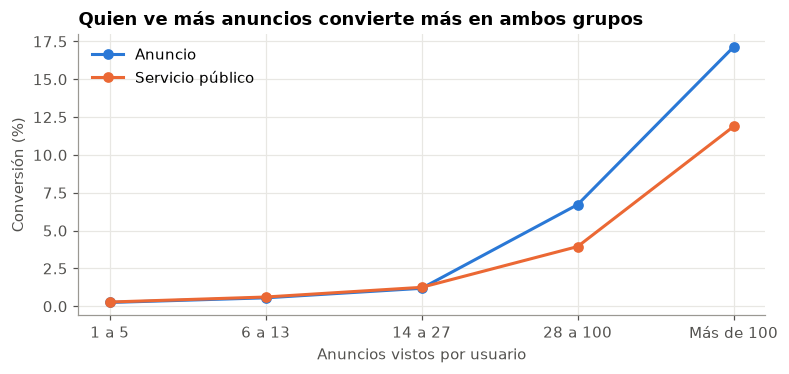

In [10]:
df['tramo'] = pd.cut(df['anuncios'], [0, 5, 13, 27, 100, 100000], labels=['1 a 5', '6 a 13', '14 a 27', '28 a 100', 'Más de 100'])
df['franja'] = pd.cut(df['hora'], [-1, 5, 11, 17, 23], labels=['Madrugada', 'Mañana', 'Tarde', 'Noche'])

def subgrupos(col, orden=None):
    filas = []
    for v, g in df.groupby(col, observed=True):
        n1, n0 = int(g['ad'].sum()), int((1 - g['ad']).sum())
        x1, x0 = int(g.loc[g['ad'] == 1, 'y'].sum()), int(g.loc[g['ad'] == 0, 'y'].sum())
        p1, p0 = x1 / n1, x0 / n0
        e_ = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
        z__ = (p1 - p0) / e_ if e_ > 0 else 0
        filas.append({'Variable': col, 'Grupo': v, 'Usuarios control': n0, 'Tasa anuncio': p1, 'Tasa control': p0, 'Efecto': p1 - p0, 'li': p1 - p0 - z_ * e_, 'ls': p1 - p0 + z_ * e_, 'p': 2 * stats.norm.sf(abs(z__))})
    return filas

sub = pd.DataFrame(subgrupos('dia') + subgrupos('franja') + subgrupos('tramo'))
sub['p_holm'] = multipletests(sub['p'], method='holm')[1]
sub['p_bh'] = multipletests(sub['p'], method='fdr_bh')[1]
vista = sub.assign(**{'Tasa anuncio': sub['Tasa anuncio'].map(lambda x: pct(x)), 'Tasa control': sub['Tasa control'].map(lambda x: pct(x)), 'Efecto': sub['Efecto'].map(lambda x: pp(x, 2)),
                      'IC 95 %': [f'{pp(a, 2)} a {pp(b, 2)}' for a, b in zip(sub['li'], sub['ls'])], 'p Holm': sub['p_holm'].map(lambda x: f'{x:.3g}')})
display(vista[['Variable', 'Grupo', 'Usuarios control', 'Tasa anuncio', 'Tasa control', 'Efecto', 'IC 95 %', 'p Holm']].set_index(['Variable', 'Grupo']))

t_ = sub[sub['Variable'] == 'tramo']
fig, ax = plt.subplots(figsize=(7.3, 3.5))
x_ = np.arange(len(t_))
ax.plot(x_, t_['Tasa anuncio'] * 100, color=AZUL, marker='o', markersize=6, label='Anuncio')
ax.plot(x_, t_['Tasa control'] * 100, color=NARANJA, marker='o', markersize=6, label='Servicio público')
ax.set_xticks(x_, t_['Grupo'].astype(str)); ax.set(xlabel='Anuncios vistos por usuario', ylabel='Conversión (%)', title='Quien ve más anuncios convierte más en ambos grupos')
ax.legend()
plt.tight_layout(); plt.show()

**Lectura.**

- **El efecto no es uniforme.** Es mayor los martes (+1.60 pp) y no se distingue de cero los jueves o domingos, aunque estas diferencias no se deben tomar como definitivas.
- **El efecto aparece con exposición alta.** Entre usuarios con hasta 27 anuncios es prácticamente cero. Con 28 a 100 anuncios es +2.77 pp, y con más de 100, +5.25 pp.
- **No significa que mostrar más anuncios cause más conversiones.** La conversión también sube mucho en el control. Los usuarios más expuestos son más activos, y los grupos dejan de ser comparables al filtrar.

Lo que sí sugiere es una hipótesis valiosa para un **nuevo experimento** que asigne al azar el número de anuncios.

## 8. Potencia y tamaño de muestra

El **efecto mínimo detectable** es la menor diferencia que se podría distinguir del azar con 80 % de potencia:

$$MDE = (z_{\alpha/2} + z_{\beta}) \sqrt{p(1-p)\left(\frac{1}{n_A}+\frac{1}{n_C}\right)}$$

El reparto importa: con un total fijo, 50/50 da la mayor precisión. Pero cada usuario en el control es uno que no ve el anuncio.

In [11]:
def mde(n1, n0, p0=pc):
    return (stats.norm.ppf(1 - ALFA / 2) + stats.norm.ppf(POTENCIA)) * np.sqrt(p0 * (1 - p0) * (1 / n1 + 1 / n0))

filas = []
for prop in [0.04, 0.10, 0.20, 0.50]:
    n0 = int(N * prop)
    filas.append({'Parte en control': pct(prop, 0), 'Usuarios control': n0, 'Efecto mínimo detectable': pp(mde(N - n0, n0)), 'Usuarios que no ven el anuncio': f'{n0:,}'})
display(pd.DataFrame(filas).set_index('Parte en control'))

filas = []
n_lift = []
for objetivo in [0.002, 0.003, 0.005, 0.0077]:
    z__ = stats.norm.ppf(1 - ALFA / 2) + stats.norm.ppf(POTENCIA)
    p_ = pc + objetivo / 2
    n_ = z__ ** 2 * 2 * p_ * (1 - p_) / objetivo ** 2
    filas.append({'Efecto a detectar': pp(objetivo, 2), 'Usuarios por grupo (50/50)': f'{int(np.ceil(n_)):,}'})
display(pd.DataFrame(filas).set_index('Efecto a detectar'))

,Usuarios control,Efecto mínimo detectable,Usuarios que no ven el anuncio
Parte en control,,,
4 %,23524,+0.247 pp,"23,524"
10 %,58810,+0.161 pp,"58,810"
20 %,117620,+0.121 pp,"117,620"
50 %,294050,+0.097 pp,"294,050"


,Usuarios por grupo (50/50)
Efecto a detectar,
+0.20 pp,"72,597"
+0.30 pp,"33,105"
+0.50 pp,"12,521"
+0.77 pp,"5,622"


**Lectura.** Con 4 % en control, el experimento detectaría efectos desde 0.247 pp, y eso bastó para el efecto observado. Con 20 % en control, el mínimo baja a 0.121 pp.

El reparto de 96/4 tiene sentido si se quiere exponer a más usuarios y se espera un efecto grande. Si se quisiera medir un efecto de solo 0.2 pp, bastarían unos 72,600 usuarios por grupo con un reparto 50/50.

## 9. Decisión económica

Un efecto real puede no ser rentable. Traducimos el efecto a dinero con un margen ilustrativo de 50 por conversión:

$$\text{Beneficio por 1,000 usuarios} = 1000 \times \text{efecto} \times \text{margen} - \text{costo}$$

Con el efecto de 0.769 pp: $1000 \times 0.00769 \times 50 = 385$. La campaña es rentable si cuesta menos de 385 por cada 1,000 usuarios.

In [12]:
filas = []
for costo in COSTOS_POR_MIL:
    post = 1000 * d_post * MARGEN_CONVERSION - costo
    filas.append({'Costo por 1,000 usuarios': costo, 'Beneficio neto esperado': round(1000 * delta * MARGEN_CONVERSION - costo),
                  'IC 95 %': f'{1000 * li * MARGEN_CONVERSION - costo:+.0f} a {1000 * ls * MARGEN_CONVERSION - costo:+.0f}',
                  'Probabilidad de beneficio positivo': pct((post > 0).mean(), 1)})
display(pd.DataFrame(filas).set_index('Costo por 1,000 usuarios'))
print(f'Costo de equilibrio por 1,000 usuarios: {1000 * delta * MARGEN_CONVERSION:.0f} (IC 95 %: {1000 * li * MARGEN_CONVERSION:.0f} a {1000 * ls * MARGEN_CONVERSION:.0f})')
print(f'Margen mínimo por conversión si el costo fuera 200 por 1,000: {200 / (1000 * delta):.1f}')

,Beneficio neto esperado,IC 95 %,Probabilidad de beneficio positivo
"Costo por 1,000 usuarios",,,
100,285,+198 a +372,100.0 %
200,185,+98 a +272,100.0 %
300,85,-2 a +172,96.6 %
400,-15,-102 a +72,35.3 %
500,-115,-202 a -28,0.3 %


Costo de equilibrio por 1,000 usuarios: 385 (IC 95 %: 298 a 472)
Margen mínimo por conversión si el costo fuera 200 por 1,000: 26.0


**Lectura.**

- **Hasta un costo de 200 por 1,000 usuarios,** el beneficio es positivo con holgura.
- **Con 300,** el beneficio esperado es 85, y su probabilidad de ser positivo es 96.6 %.
- **Con 400,** la campaña pierde 15 en promedio, y su probabilidad de ganar baja a 35.3 %.

El punto de equilibrio está entre 298 y 472 según el intervalo. Esta es la cifra que debería decidir la campaña, una vez reemplazados el costo y el margen reales.

## 10. Limitaciones

- **Sin protocolo.** No sabemos cómo se asignaron los grupos ni qué reparto se planificó.
- **El control ve otro anuncio.** No medimos el efecto frente a no mostrar nada, y el anuncio de servicio público podría influir por sí mismo.
- **Sin fechas ni ventana de conversión.** No podemos ver si el efecto dura, si hubo interrupciones anticipadas ni cuánto tiempo se observó a cada usuario.
- **Sin variables previas.** No se puede comprobar el balance en características anteriores al experimento.
- **Interferencia.** Se supone que lo que ve un usuario no afecta a otro.
- **Economía supuesta.** Costos y márgenes son ilustrativos.
- **Un caso publicitario general.** Los resultados no se pueden extrapolar a productos bancarios.

## Conclusión

**El anuncio aumenta la conversión en 0.769 pp** (IC 95 %: 0.595 a 0.943), un aumento relativo de 43.1 %. Métodos distintos llegan a la misma conclusión, y ajustar por otras variables casi no cambia el resultado.

**Recomendación.** Escalar la campaña si su costo está claramente por debajo del punto de equilibrio, cercano a 385 por 1,000 usuarios con el margen ilustrativo. Antes, confirmar con el equipo responsable el protocolo de asignación, el reparto previsto y la ventana de conversión.

**Siguiente experimento.** Asignar al azar la frecuencia de anuncios para saber si realmente conviene mostrar más, y usar un control mayor si se buscan efectos pequeños.

**Las ideas para llevarse**

1. Audita el experimento antes de mirar el resultado.
2. Con muestras enormes, casi todo es significativo: mira también la magnitud.
3. No filtres por variables posteriores a la asignación si quieres una conclusión causal.
4. Un subgrupo llamativo es una hipótesis, no un hallazgo.
5. Un efecto estadísticamente claro todavía debe ser rentable.

## Ejercicios

1. **Cambia `MARGEN_CONVERSION` a 25.** ¿Cuál es el nuevo punto de equilibrio?
2. **Cambia `ALFA` a 0.01.** ¿Cambia alguna conclusión?
3. **Sin la corrección de Holm,** ¿cuántos subgrupos parecerían significativos?
4. **Reduce el control** tomando una muestra de 2,000 usuarios `psa`. ¿Qué pasa con el intervalo?
5. **Compara a usuarios con más de 100 anuncios contra el resto,** sin mirar el grupo. ¿Por qué esa diferencia no es un efecto causal?
6. **Para pensar:** si el anuncio solo funciona con alta exposición, ¿qué experimento diseñarías?